# Penerapan Data Mining untuk Klasifikasi Evaluasi Kelayakan Mobil Menggunakan Algoritma Decision Tree

## 1. Gambaran Permasalahan

Evaluasi kelayakan mobil merupakan salah satu aspek yang dapat dipertimbangkan dalam proses pengambilan keputusan terkait pemilihan kendaraan. Penilaian terhadap mobil dapat didasarkan pada beberapa karakteristik, seperti harga pembelian, biaya perawatan, jumlah pintu, kapasitas penumpang, ukuran bagasi, dan tingkat keselamatan.

Permasalahan yang dihadapi adalah bagaimana mengidentifikasi pola hubungan antara karakteristik tersebut dan kategori evaluasi mobil. Data Mining dapat digunakan untuk menggali pola dari kumpulan data evaluasi mobil melalui teknik klasifikasi. Dalam penerapannya, algoritma Decision Tree digunakan untuk membangun model yang dapat mengelompokkan mobil ke dalam empat kategori evaluasi, yaitu *unacc* (tidak dapat diterima), *acc* (dapat diterima), *good* (baik), dan *vgood* (sangat baik).

Melalui penerapan teknik klasifikasi ini, diharapkan dapat diketahui sejauh mana karakteristik mobil dapat digunakan untuk memprediksi kategori evaluasinya. Hasil analisis kemudian dievaluasi menggunakan metrik klasifikasi untuk mengetahui kinerja model dalam mengelompokkan data.



## 2. Tujuan Analisis

Analisis ini bertujuan menerapkan teknik klasifikasi dalam Data Mining untuk mengidentifikasi pola hubungan antara karakteristik mobil dan kategori evaluasinya. Algoritma Decision Tree digunakan untuk membangun model klasifikasi yang dapat mengelompokkan mobil ke dalam kategori *unacc*, *acc*, *good*, dan *vgood*. Kinerja model selanjutnya dievaluasi menggunakan metrik akurasi, precision, recall, dan F1-score.


## 3. Deskripsi Dataset

Dataset *Car Evaluation* berasal dari UCI Machine Learning Repository. Dataset ini dikembangkan berdasarkan model keputusan untuk mengevaluasi mobil menggunakan sejumlah atribut yang berkaitan dengan harga, kapasitas, dan keselamatan kendaraan.

Dataset terdiri atas 1.728 observasi, enam atribut prediktor kategorikal, dan satu variabel target yang menunjukkan kategori evaluasi mobil.

Atribut yang digunakan meliputi:

* **Buying:** tingkat harga pembelian mobil.
* **Maint:** tingkat biaya perawatan mobil.
* **Doors:** jumlah pintu mobil.
* **Persons:** kapasitas penumpang.
* **Lug_boot:** ukuran bagasi.
* **Safety:** tingkat keselamatan mobil.

Variabel target, yaitu **Class**, memiliki empat kategori: *unacc* (unacceptable), *acc* (acceptable), *good*, dan *vgood* (very good).

Sumber dataset: [UCI Machine Learning Repository — Car Evaluation](https://archive.ics.uci.edu/dataset/19/car+evaluation).


## 4. Metode Klasifikasi yang Digunakan

Untuk metode klasifikasinya, aku menyarankan Decision Tree Classifier.

Decision Tree merupakan algoritma klasifikasi yang membentuk struktur pohon keputusan berdasarkan atribut-atribut dalam dataset. Model mempelajari aturan pemisahan data untuk memprediksi kategori evaluasi mobil.

Metode ini cocok untuk dataset Car Evaluation karena seluruh atribut prediktornya bersifat kategorikal dan hasil model relatif mudah diinterpretasikan.

Tahapan analisis yang akan kita kerjakan adalah:

* Import library Python
*	Memuat dataset
*	Memahami struktur dan distribusi data
*	Melakukan preprocessing
*	Membagi data latih dan data uji
*	Membangun model Decision Tree
*	Melakukan prediksi
*	Mengevaluasi hasil klasifikasi
*	Membahas hasil, manfaat, dan keterbatasan model

Catatan teknis: Dataset Car Evaluation menggunakan atribut kategorikal. Karena itu, kita perlu mengubah atribut tersebut menjadi representasi numerik menggunakan encoding sebelum melatih model.

## 5. Implementasi

### 5.1 Import Library

In [1]:
pip install ucimlrepo

In [2]:
# Import library
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

### 5.2 Memuat Dataset

In [3]:
# Mengambil dataset Car Evaluation dari UCI
car_evaluation = fetch_ucirepo(id=19)

# Memisahkan fitur dan target
X = car_evaluation.data.features
y = car_evaluation.data.targets

# Menggabungkan fitur dan target
df = pd.concat([X, y], axis=1)

# Menampilkan lima baris pertama
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


### 5.3 Memeriksa Struktur Dataset

In [4]:
# Menampilkan dimensi dataset
print("Dimensi dataset:", df.shape)

# Menampilkan informasi dataset
df.info()

# Memeriksa jumlah nilai yang hilang
print("\nJumlah missing values:")
print(df.isnull().sum())

# Memeriksa jumlah data duplikat
print("\nJumlah data duplikat:", df.duplicated().sum())

Dimensi dataset: (1728, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB

Jumlah missing values:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

Jumlah data duplikat: 0


### 5.4 Memeriksa Distribusi Kelas

Distribusi kelas evaluasi mobil:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


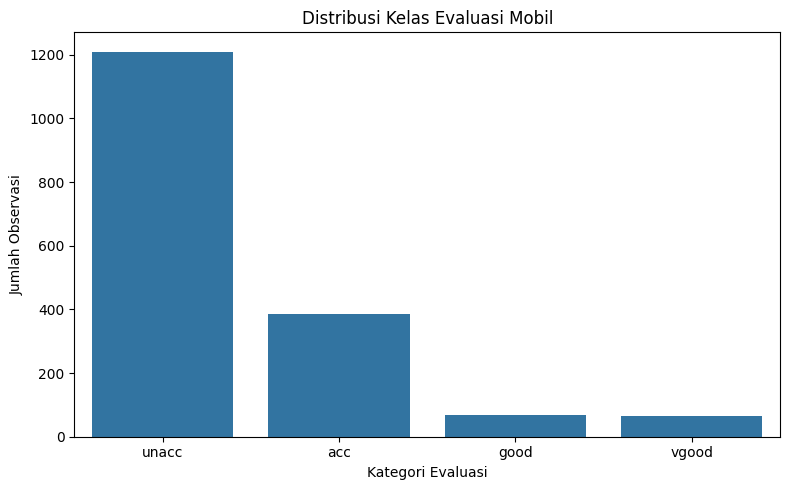

In [5]:
# Menghitung jumlah data pada setiap kelas
class_counts = df["class"].value_counts()

print("Distribusi kelas evaluasi mobil:")
print(class_counts)

# Visualisasi distribusi kelas
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="class", order=class_counts.index)

plt.title("Distribusi Kelas Evaluasi Mobil")
plt.xlabel("Kategori Evaluasi")
plt.ylabel("Jumlah Observasi")
plt.tight_layout()
plt.show()

In [6]:
df.head()
df.shape
df["class"].value_counts()

,count
class,
unacc,1210
acc,384
good,69
vgood,65


### 5.5 Analisis Distribusi Kelas

Berdasarkan hasil pemeriksaan distribusi kelas, dataset Car Evaluation terdiri atas 1.728 observasi yang terbagi menjadi empat kategori evaluasi mobil. Kategori *unacc* memiliki jumlah observasi terbanyak, yaitu 1.210 data (70,02%), diikuti kategori *acc* sebanyak 384 data (22,22%). Sementara itu, kategori *good* dan *vgood* masing-masing memiliki 69 data (3,99%) dan 65 data (3,76%).

Distribusi tersebut menunjukkan adanya ketidakseimbangan kelas dalam dataset. Kondisi ini perlu diperhatikan pada tahap pemodelan karena model berpotensi lebih baik dalam mengenali kelas mayoritas dibandingkan kelas minoritas. Oleh karena itu, evaluasi model tidak hanya didasarkan pada accuracy, tetapi juga mempertimbangkan precision, recall, F1-score, dan confusion matrix.


## 6. Preprocessing Data

### 6.1 Memeriksa Tipe Data dan Nilai Unik

In [7]:
# Memeriksa tipe data setiap kolom
print("Tipe data:")
print(df.dtypes)

# Memeriksa nilai unik setiap kolom
print("\nJumlah nilai unik setiap kolom:")
print(df.nunique())

# Memeriksa nilai unik pada setiap atribut
for column in df.columns:
    print(f"\n{column}:")
    print(df[column].unique())

Tipe data:
buying      object
maint       object
doors       object
persons     object
lug_boot    object
safety      object
class       object
dtype: object

Jumlah nilai unik setiap kolom:
buying      4
maint       4
doors       4
persons     3
lug_boot    3
safety      3
class       4
dtype: int64

buying:
['vhigh' 'high' 'med' 'low']

maint:
['vhigh' 'high' 'med' 'low']

doors:
['2' '3' '4' '5more']

persons:
['2' '4' 'more']

lug_boot:
['small' 'med' 'big']

safety:
['low' 'med' 'high']

class:
['unacc' 'acc' 'vgood' 'good']


### 6.2 Memisahkan Fitur dan Target

In [8]:
# Memisahkan fitur dan target
X = df.drop(columns=["class"])
y = df["class"]

# Menampilkan dimensi fitur dan target
print("Dimensi fitur:", X.shape)
print("Dimensi target:", y.shape)

# Menampilkan nama fitur
print("\nAtribut prediktor:")
print(X.columns.tolist())

Dimensi fitur: (1728, 6)
Dimensi target: (1728,)

Atribut prediktor:
['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']


### 6.3 Encoding Atribut Kategorikal

In [9]:
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder

# Encoding fitur kategorikal
encoder_X = OrdinalEncoder()
X_encoded = pd.DataFrame(
    encoder_X.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# Encoding variabel target
encoder_y = LabelEncoder()
y_encoded = encoder_y.fit_transform(y)

# Menampilkan hasil encoding
print("Contoh fitur setelah encoding:")
display(X_encoded.head())

print("\nPemetaan kategori target:")
for label, encoded_value in zip(
    encoder_y.classes_,
    encoder_y.transform(encoder_y.classes_)
):
    print(f"{label} = {encoded_value}")

Contoh fitur setelah encoding:


,buying,maint,doors,persons,lug_boot,safety
0,3.0,3.0,0.0,0.0,2.0,1.0
1,3.0,3.0,0.0,0.0,2.0,2.0
2,3.0,3.0,0.0,0.0,2.0,0.0
3,3.0,3.0,0.0,0.0,1.0,1.0
4,3.0,3.0,0.0,0.0,1.0,2.0



Pemetaan kategori target:
acc = 0
good = 1
unacc = 2
vgood = 3


**Catatan**: Encoding ini memberikan kode numerik pada kategori yang tersedia. Nilai kodenya bukan ukuran kuantitatif kualitas mobil. Pada tahap pemodelan, kita akan menggunakan pembagian data yang terstratifikasi agar proporsi setiap kelas relatif terjaga pada data latih dan data uji.

## 7. Pembagian Data Latih dan Data Uji

### 7.1 Pembagian Data

Dataset dibagi menjadi data latih sebesar 80% dan data uji sebesar 20%. Data latih digunakan untuk membangun model klasifikasi, sedangkan data uji digunakan untuk mengevaluasi kinerja model terhadap data yang tidak digunakan selama proses pelatihan.

Pembagian dilakukan menggunakan teknik stratifikasi (stratified sampling) agar proporsi setiap kategori evaluasi mobil tetap terjaga pada data latih dan data uji.

In [10]:
from sklearn.model_selection import train_test_split

# Membagi dataset menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Menampilkan ukuran data
print("Jumlah data keseluruhan:", len(X_encoded))
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data keseluruhan: 1728
Jumlah data latih: 1382
Jumlah data uji: 346


## 8. Pembangunan Model Decision Tree

Decision Tree membentuk struktur pohon berdasarkan aturan pemisahan atribut. Setiap percabangan merepresentasikan kondisi tertentu, sedangkan simpul akhir (leaf node) menunjukkan kelas prediksi.

### 8.1 Penerapan Algoritma Decision Tree

Algoritma Decision Tree Classifier digunakan untuk mempelajari pola hubungan antara atribut kendaraan dan kategori evaluasi mobil. Model membentuk aturan keputusan berdasarkan karakteristik seperti harga pembelian, biaya perawatan, kapasitas penumpang, ukuran bagasi, jumlah pintu, dan tingkat keselamatan.

Parameter `random_state=42` digunakan untuk mendukung reproduksibilitas hasil, sedangkan `criterion="gini"` menentukan penggunaan Gini impurity sebagai kriteria pemilihan pemisahan atribut.


In [11]:
from sklearn.tree import DecisionTreeClassifier

# Membuat model Decision Tree
model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# Melatih model menggunakan data latih
model.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih.")

Model Decision Tree berhasil dilatih.


### 8.2 Melakukan Prediksi

In [12]:
# Melakukan prediksi pada data uji
y_pred = model.predict(X_test)

# Menampilkan beberapa hasil prediksi
hasil_prediksi = pd.DataFrame({
    "Kelas Aktual": encoder_y.inverse_transform(y_test),
    "Kelas Prediksi": encoder_y.inverse_transform(y_pred)
})

display(hasil_prediksi.head(10))

,Kelas Aktual,Kelas Prediksi
0,good,good
1,unacc,unacc
2,unacc,unacc
3,unacc,unacc
4,acc,acc
5,unacc,unacc
6,unacc,unacc
7,acc,acc
8,unacc,unacc
9,unacc,unacc


## 9. Evaluasi Model

Tahap berikutnya adalah mengevaluasi kinerja model. Kita akan menggunakan empat metrik utama dan confusion matrix.

### 9.1 Metrik Evaluasi

Kinerja model dievaluasi menggunakan accuracy, precision, recall, dan F1-score. Accuracy mengukur proporsi prediksi yang benar dari seluruh observasi. Precision menunjukkan ketepatan prediksi pada suatu kelas, sedangkan recall mengukur kemampuan model mengenali seluruh observasi yang benar-benar termasuk dalam kelas tersebut.

F1-score merupakan rata-rata harmonik antara precision dan recall. Selain itu, confusion matrix digunakan untuk mengetahui jumlah prediksi yang benar maupun kesalahan klasifikasi pada setiap kategori evaluasi mobil.


In [13]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Menghitung accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy (%): {accuracy * 100:.2f}%")

# Menampilkan classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=range(len(encoder_y.classes_)),
        target_names=encoder_y.classes_,
        zero_division=0
    )
)

Accuracy: 0.9855
Accuracy (%): 98.55%

Classification Report:
              precision    recall  f1-score   support

         acc       0.95      0.99      0.97        77
        good       0.93      1.00      0.97        14
       unacc       1.00      0.99      1.00       242
       vgood       1.00      0.85      0.92        13

    accuracy                           0.99       346
   macro avg       0.97      0.96      0.96       346
weighted avg       0.99      0.99      0.99       346



### 9.2 Confusion Matrix

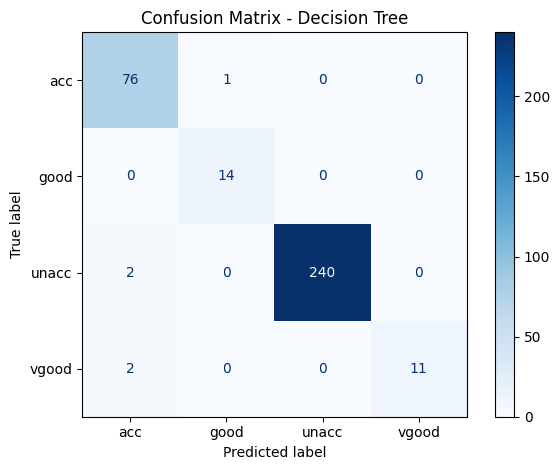

In [14]:
# Membuat confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(encoder_y.classes_))
)

# Menampilkan visualisasi confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder_y.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Decision Tree")
plt.tight_layout()
plt.show()

## 10. Hasil dan Pembahasan

### 10.1 Hasil Evaluasi Model

Berdasarkan pengujian menggunakan 346 data uji, model Decision Tree Classifier memperoleh accuracy sebesar 98,55%. Hasil ini menunjukkan bahwa model berhasil mengklasifikasikan sebagian besar observasi sesuai dengan kategori evaluasi mobil yang sebenarnya.

Berdasarkan classification report, kelas *unacc* memperoleh precision sebesar 1,00, recall sebesar 0,99, dan F1-score sebesar 1,00. Pada kelas *acc*, model menghasilkan precision sebesar 0,95, recall sebesar 0,99, dan F1-score sebesar 0,97. Sementara itu, kelas *good* memperoleh precision sebesar 0,93, recall sebesar 1,00, dan F1-score sebesar 0,97.

Kelas *vgood* memperoleh precision sebesar 1,00, recall sebesar 0,85, dan F1-score sebesar 0,92. Hasil tersebut menunjukkan bahwa seluruh prediksi model untuk kelas *vgood* benar pada data uji ini, tetapi model belum berhasil mengenali seluruh observasi yang sebenarnya termasuk dalam kategori tersebut.

Secara keseluruhan, model menunjukkan kinerja klasifikasi yang tinggi. Meskipun demikian, hasil evaluasi perlu ditafsirkan dengan mempertimbangkan distribusi kelas yang tidak seimbang. Kelas *unacc* memiliki jumlah observasi jauh lebih banyak dibandingkan kelas *good* dan *vgood*, sehingga accuracy saja belum cukup untuk menggambarkan kemampuan model secara menyeluruh.


## 11. Visualisasi Pohon Keputusan

Agar penerapan Machine Learning lebih jelas, kita visualisasikan pohon keputusan yang dibentuk oleh model.

### 11.1 Visualisasi Model Decision Tree

Visualisasi pohon keputusan digunakan untuk melihat aturan pemisahan atribut yang dipelajari model selama proses pelatihan. Melalui visualisasi ini, proses pengambilan keputusan model dapat diamati berdasarkan kondisi atribut kendaraan dan kategori evaluasi yang diprediksi.


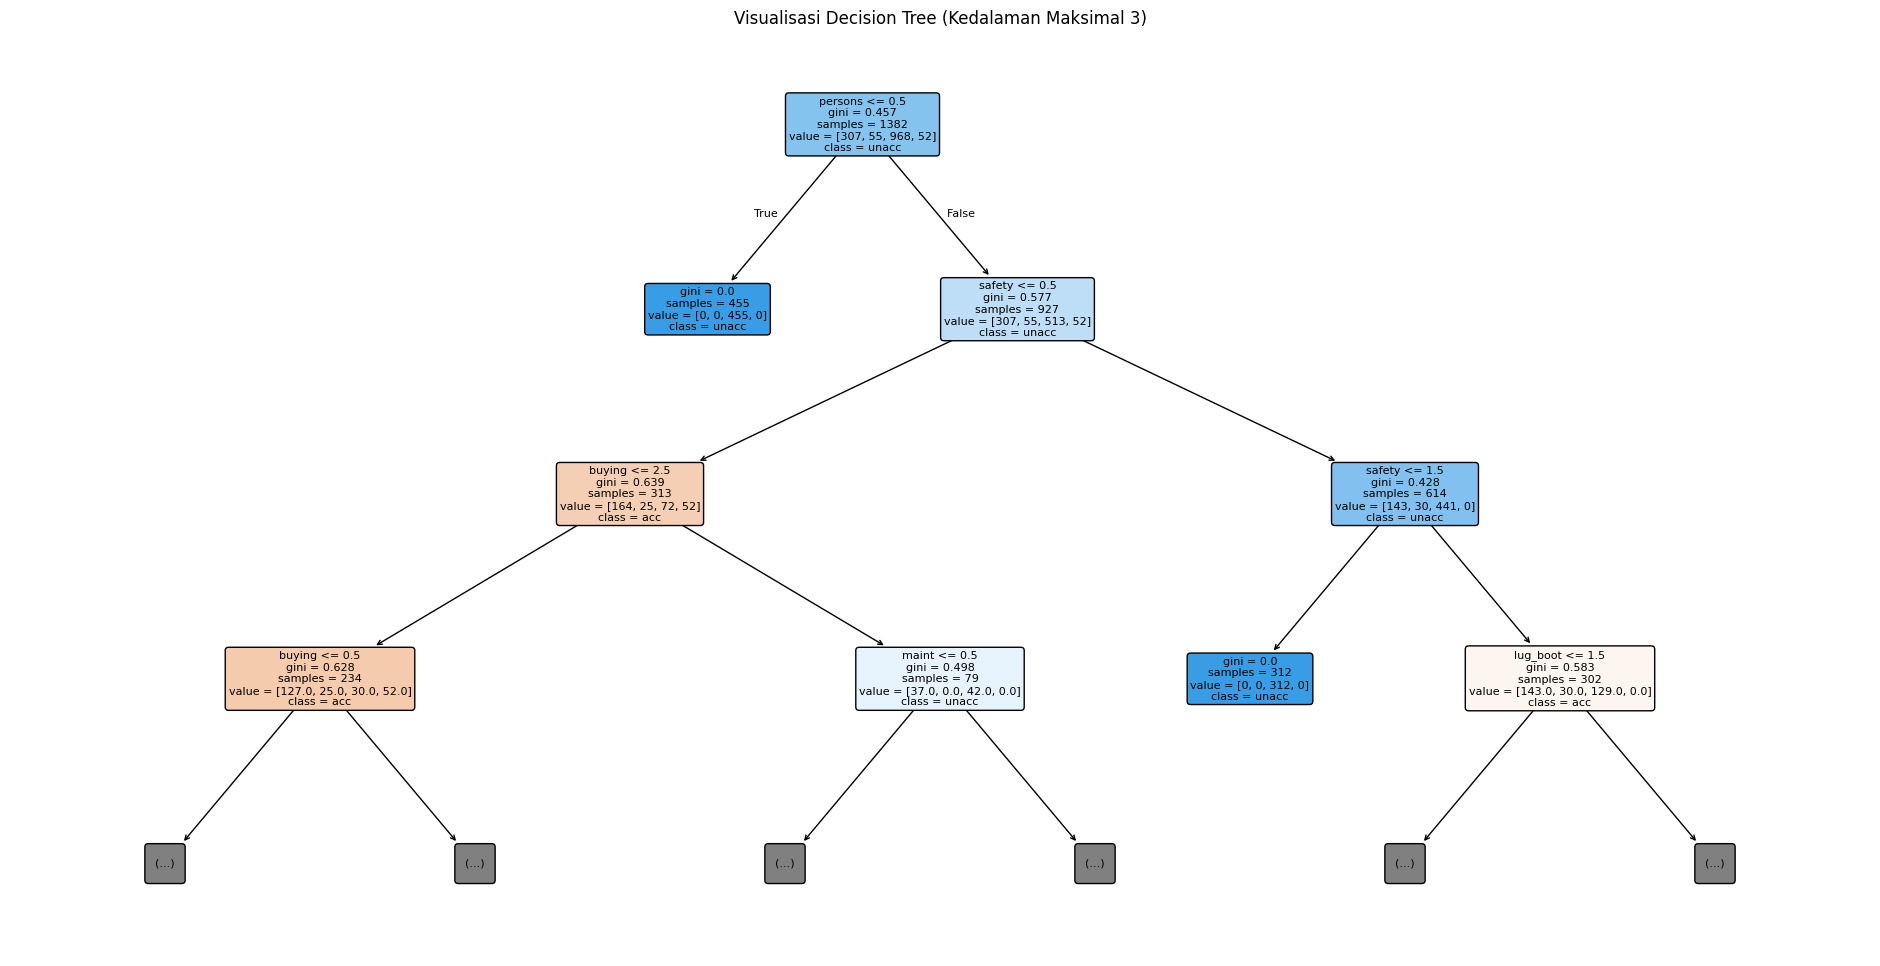

In [15]:
from sklearn.tree import plot_tree

# Membuat visualisasi pohon keputusan
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=encoder_y.classes_,
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Visualisasi Decision Tree (Kedalaman Maksimal 3)")
plt.show()

## 12. Manfaat dan Keterbatasan

### 12.1 Manfaat

Penerapan Machine Learning menggunakan algoritma Decision Tree pada dataset Car Evaluation memberikan beberapa manfaat:

1. **Membantu proses evaluasi kendaraan.** Model dapat memprediksi kategori evaluasi mobil berdasarkan karakteristik harga, biaya perawatan, kapasitas penumpang, ukuran bagasi, dan keselamatan.
2. **Mendukung pengambilan keputusan.** Hasil klasifikasi dapat digunakan sebagai informasi pendukung dalam memahami hubungan antara karakteristik kendaraan dan kategori evaluasinya.
3. **Menyediakan model yang mudah diinterpretasikan.** Struktur pohon keputusan memungkinkan aturan klasifikasi dipelajari dan divisualisasikan.
4. **Menghasilkan performa klasifikasi yang tinggi.** Model memperoleh accuracy sebesar 98,55% pada data uji dalam eksperimen ini.

### 12.2 Keterbatasan

Meskipun menghasilkan accuracy yang tinggi, model memiliki beberapa keterbatasan. Dataset menunjukkan ketidakseimbangan distribusi kelas, terutama karena kategori *unacc* mendominasi jumlah observasi. Selain itu, recall kelas *vgood* sebesar 0,85 menunjukkan bahwa masih terdapat observasi dalam kategori tersebut yang salah diklasifikasikan.

Hasil ini juga terbatas pada atribut dan kategori yang tersedia dalam dataset. Oleh karena itu, model tidak dapat langsung dianggap sebagai sistem penilaian kendaraan yang berlaku secara umum tanpa pengujian lebih lanjut pada data dan konteks penggunaan yang berbeda.


## 13. Kesimpulan

Penerapan Machine Learning menggunakan algoritma Decision Tree Classifier pada dataset Car Evaluation berhasil menghasilkan model klasifikasi dengan accuracy sebesar 98,55% pada 346 observasi data uji. Model digunakan untuk mengklasifikasikan mobil ke dalam empat kategori evaluasi, yaitu *unacc*, *acc*, *good*, dan *vgood*, berdasarkan enam atribut karakteristik kendaraan.

Hasil evaluasi menunjukkan bahwa model memiliki performa tinggi pada seluruh kelas, meskipun recall kategori *vgood* sebesar 0,85 masih lebih rendah dibandingkan kategori lainnya. Temuan ini menunjukkan pentingnya menggunakan beberapa metrik evaluasi, bukan hanya accuracy, terutama ketika dataset memiliki distribusi kelas yang tidak seimbang.

Secara keseluruhan, eksperimen ini memperlihatkan bahwa Decision Tree dapat digunakan untuk mempelajari pola klasifikasi evaluasi mobil dan menghasilkan aturan keputusan yang dapat divisualisasikan. Namun, hasil tersebut terbatas pada dataset yang digunakan dan belum membuktikan bahwa model dapat diterapkan secara langsung pada seluruh kondisi evaluasi kendaraan.


## 14. Referensi

1. Bohanec, M., & Rajkovič, V. (1988). Knowledge acquisition and explanation for multi-attribute decision making. *Proceedings of the 8th International Workshop on Expert Systems and Their Applications*, 59–78.
2. UCI Machine Learning Repository. *Car Evaluation*. https://archive.ics.uci.edu/dataset/19/car+evaluation
3. Scikit-learn Developers. *DecisionTreeClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
4. Scikit-learn Developers. *Model Evaluation: Quantifying the Quality of Predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html
5. Scikit-learn Developers. *train_test_split*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
